# 01 · Tổng quan về dữ liệu của nhóm

Trước khi viết bước QA (kiểm tra chất lượng dữ liệu), tính KPI (các chỉ số đo lường cho bên đặt hàng) hay gọi LLM, cả nhóm cần nhìn cùng một bức tranh về dữ liệu: Có những file nào, mỗi file chứa gì,
các file nối với nhau bằng cột nào, và phần nào thật sự thuộc về nhóm 15. Notebook này trả lời bốn câu hỏi đó, còn các notebook
sau đi sâu vào từng bảng.

| Notebook | Nội dung |
|---|---|
| 01 · Tổng quan (file này) | Mười sáu file raw, ba file phân công và cách các bảng nối với nhau |
| 02 · Listings | Các cột mô tả chỗ ở, cột nào dùng được, giá ở mốc cuối có vấn đề gì |
| 03 · Calendar | Lịch 365 ngày cho biết gì về mức độ sẵn có, và không cho biết gì |
| 04 · Reviews | Đặc điểm của 5.000 review được giao trước khi đưa vào LLM |
| 05 · Không gian | Ranh giới quận trong GeoJSON và tám vùng A01–A08 |
| 06 · Tổng hợp | Toàn bộ phát hiện, các cờ đề xuất cho QA và gợi ý cho KPI, LLM |

Các notebook chỉ đọc từ `data/raw/` và `data/assignment/`, không ghi file nào vào dự án. Muốn chạy lại thì chọn *Run All*.
Notebook 03 và 04 mất khoảng hai phút vì phải lọc file calendar và reviews của cả thành phố.

Trong bộ notebook, cụm **đề yêu cầu** dùng cho điều đề bài bắt buộc, còn **đề xuất** là gợi ý của người khảo sát để nhóm cân nhắc.
Những câu còn lại mô tả đúng kết quả mà code in ra.

## 1. Thiết lập chung

Ô dưới đây lặp lại ở đầu mọi notebook. Nó tìm thư mục gốc của dự án, đọc `configs/london.yaml` để lấy tên thành phố và các mốc,
rồi đọc ba file phân công. Ngày và tên thành phố không được ghi sẵn trong code mà lấy từ file cấu hình, nên muốn khảo sát mốc khác thì chỉ cần đổi file đó.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

TEN_CAU_HINH = "london.yaml"   # Đổi file cấu hình ở đây nếu khảo sát thành phố/mốc khác.


def tim_thu_muc_du_an(thu_muc_bat_dau: Path) -> Path:
    """Đi ngược lên các thư mục cha cho tới khi gặp configs/<TEN_CAU_HINH>."""
    # Vòng lặp qua các thư mục cha (vài cấp), không phải qua dòng dữ liệu.
    for thu_muc in [thu_muc_bat_dau, *thu_muc_bat_dau.parents]:
        if (thu_muc / "configs" / TEN_CAU_HINH).is_file():
            return thu_muc

    raise FileNotFoundError(f"Không tìm thấy thư mục dự án chứa configs/{TEN_CAU_HINH}")


THU_MUC_DU_AN = tim_thu_muc_du_an(Path.cwd().resolve())

with (THU_MUC_DU_AN / "configs" / TEN_CAU_HINH).open("r", encoding="utf-8-sig") as f:
    cau_hinh = yaml.safe_load(f)

thanh_pho = cau_hinh["city"]
snapshots = [str(snapshot) for snapshot in cau_hinh["snapshots"]]   # YAML đọc ngày không nháy thành date
moc_gia = max(snapshots)   # Quy tắc của nhóm: chỉ mốc cuối được dùng giá
THU_MUC_RAW = THU_MUC_DU_AN / "data" / "raw" / thanh_pho
THU_MUC_PHAN_CONG = THU_MUC_DU_AN / "data" / "assignment"

phan_cong_listings = pd.read_csv(THU_MUC_PHAN_CONG / "listings.csv", dtype=str, keep_default_na=False)
phan_cong_reviews = pd.read_csv(THU_MUC_PHAN_CONG / "reviews.csv", dtype=str, keep_default_na=False)
phan_cong_vung = pd.read_csv(THU_MUC_PHAN_CONG / "areas.csv", dtype={"analysis_area": str}, keep_default_na=False)
cac_listing_id = set(phan_cong_listings["listing_id"])
cac_review_id = set(phan_cong_reviews["review_id"])

print("Thư mục dự án :", THU_MUC_DU_AN.name)
print("Thành phố     :", thanh_pho, "| tiền tệ:", cau_hinh["currency"])
print("Các mốc       :", snapshots, "| mốc dùng giá:", moc_gia)
print("Phân công     :", len(cac_listing_id), "listing,", len(cac_review_id), "review")

Thư mục dự án : 2627-LTXLDL-Airbnb-dse2049_7-nhom15
Thành phố     : london | tiền tệ: GBP
Các mốc       : ['2025-09-14', '2025-12-13', '2026-03-21', '2026-06-19'] | mốc dùng giá: 2026-06-19
Phân công     : 1000 listing, 5000 review


## 2. Mười sáu file raw

Inside Airbnb công bố dữ liệu theo từng lần chụp (snapshot). Mỗi lần chụp có bốn file, và nhóm dùng bốn lần chụp, nên tổng cộng có
mười sáu file. Ô sau liệt kê dung lượng của chúng.

In [2]:
MO_TA_FILE = {
    "listings.csv.gz": "Mỗi dòng là một chỗ ở tại thời điểm chụp (khoảng 80–90 cột)",
    "calendar.csv.gz": "Mỗi dòng là một chỗ ở trong một ngày của 365 ngày tới",
    "reviews.csv.gz": "Mỗi dòng là một review khách đã viết, kèm nội dung",
    "neighbourhoods.geojson": "Ranh giới 33 quận (borough) của London",
}

cac_dong = []
# Vòng lặp qua 16 file (4 mốc × 4 file) để lấy dung lượng, không phải qua dòng dữ liệu.
for snapshot in snapshots:
    for ten_file, mo_ta in MO_TA_FILE.items():
        duong_dan = THU_MUC_RAW / snapshot / ten_file
        cac_dong.append({
            "snapshot": snapshot,
            "file": ten_file,
            "co_file": duong_dan.is_file(),
            "MB": round(duong_dan.stat().st_size / 1024**2, 1) if duong_dan.is_file() else None,
            "mo_ta": mo_ta,
        })

bang_file = pd.DataFrame(cac_dong)
bang_file.pivot(index="file", columns="snapshot", values="MB")

snapshot,2025-09-14,2025-12-13,2026-03-21,2026-06-19
file,,,,
calendar.csv.gz,77.8,83.0,46.5,78.6
listings.csv.gz,48.1,43.1,29.7,48.0
neighbourhoods.geojson,1.0,1.0,1.0,1.0
reviews.csv.gz,246.1,249.1,188.1,264.1


Cả mười sáu file đều có mặt. Reviews là file nặng nhất, khoảng 190–265 MB mỗi mốc dù đã nén, vì nó chứa toàn bộ nội dung review
của cả London từ năm 2010. Đọc nguyên một file như vậy vào bộ nhớ vừa tốn vừa không cần. Pipeline nên đọc lần lượt từng phần nhỏ (chunk), giữ lại
các dòng thuộc nhóm rồi bỏ phần còn lại.

Các file của mốc 2026-03-21 nhẹ hơn hẳn ba mốc kia, ở cả listings, calendar lẫn reviews (giảm 25–45% so với mốc liền trước).
Dữ liệu không cho biết nguyên nhân của mức giảm này. Notebook 02 cho thấy số listing toàn thành phố ở mốc này cũng giảm mạnh,
nên khi dùng số liệu toàn thành phố của mốc 2026-03-21 cần thận trọng.

Đuôi `.csv.gz` chỉ có nghĩa là file CSV được nén bằng gzip. Việc nén không làm mất thông tin, và pandas đọc thẳng được file nén.

## 3. Ba file phân công của nhóm

Dữ liệu raw là của cả London, khoảng chín mươi nghìn chỗ ở. Nhóm 15 chỉ được giao một phần, và phần đó được ghi trong ba file
nhỏ ở `data/assignment/`.

In [3]:
print("listings.csv :", phan_cong_listings.shape, "| cột:", list(phan_cong_listings.columns))
print("reviews.csv  :", phan_cong_reviews.shape, "| cột:", list(phan_cong_reviews.columns))
print("areas.csv    :", phan_cong_vung.shape, "| cột:", list(phan_cong_vung.columns))
phan_cong_reviews.head()

listings.csv : (1000, 2) | cột: ['listing_id', 'analysis_area']
reviews.csv  : (5000, 4) | cột: ['review_id', 'listing_id', 'llm_sample', 'human_sample']
areas.csv    : (8, 5) | cột: ['analysis_area', 'lon_min', 'lat_min', 'lon_max', 'lat_max']


,review_id,listing_id,llm_sample,human_sample
0,604924,227502,False,False
1,2423254,227502,False,False
2,2586842,538558,False,False
3,2744638,538558,True,False
4,3006137,538558,False,False


In [4]:
mau_llm = phan_cong_reviews["llm_sample"].eq("True")
mau_nhan_tay = phan_cong_reviews["human_sample"].eq("True")

print("Listing ID khác nhau            :", phan_cong_listings["listing_id"].nunique())
print("Review ID khác nhau             :", phan_cong_reviews["review_id"].nunique())
print("Review thuộc mẫu LLM            :", mau_llm.sum())
print("Review thuộc mẫu nhãn tay       :", mau_nhan_tay.sum())
print("Nhãn tay nằm ngoài mẫu LLM      :", (mau_nhan_tay & ~mau_llm).sum())
print("Review trỏ tới listing ngoài nhóm:", (~phan_cong_reviews["listing_id"].isin(cac_listing_id)).sum())
print("Listing có ít nhất 1 review giao :", phan_cong_reviews["listing_id"].nunique())

pd.crosstab(mau_llm.rename("llm_sample"), mau_nhan_tay.rename("human_sample"), margins=True)

Listing ID khác nhau            : 1000
Review ID khác nhau             : 5000
Review thuộc mẫu LLM            : 1000
Review thuộc mẫu nhãn tay       : 100
Nhãn tay nằm ngoài mẫu LLM      : 0
Review trỏ tới listing ngoài nhóm: 0
Listing có ít nhất 1 review giao : 701


human_sample,False,True,All
llm_sample,,,
False,4000,0,4000
True,900,100,1000
All,4900,100,5000


Dòng cuối của phần in ra dễ bị bỏ qua: 5.000 review chỉ thuộc về 701 trên 1.000 listing, nghĩa là gần ba trăm chỗ ở của nhóm không có review
nào được giao. Ô tiếp theo cho thấy độ phủ còn hẹp hơn ở hai tập con. Mẫu 1.000 review chạy LLM chỉ đến từ 375 listing, và 100 review gán nhãn tay
chỉ đến từ 85 listing. Vì vậy, khi giải thích một KPI xây trên kết quả LLM, cần nói rõ nó tính trên tập nào và phủ bao nhiêu listing.

**Cách đọc biểu đồ.** Mỗi cột ứng với đúng một số review: Cột ở vị trí 1 đếm những listing được giao một review, cột ở vị trí 2 đếm những listing được giao hai review, và cứ thế tiếp tục. Chiều cao của cột là số listing rơi vào mức đó. 299 listing không được giao review nào nên không có mặt trên biểu đồ. Khi đọc, hãy để ý các cột cao dồn về phía nào và phần đuôi bên phải kéo dài tới đâu: Đuôi càng dài thì càng có ít listing nắm phần lớn số review.

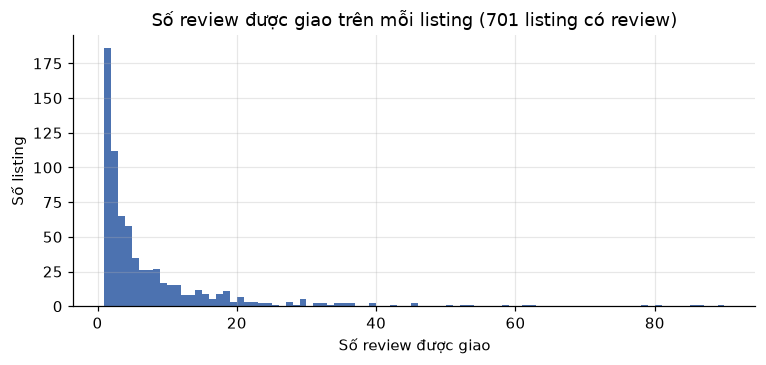

,so_review,so_listing_co_review,ti_le_review_cua_10%_listing_dong_nhat
5.000 được giao,5000,701,0.453
mẫu LLM,1000,375,0.356
mẫu nhãn tay,100,85,NaN


In [5]:
so_review_moi_listing = phan_cong_reviews.groupby("listing_id").size().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.hist(so_review_moi_listing, bins=range(1, so_review_moi_listing.max() + 2), color="#4C72B0")
ax.set(title="Số review được giao trên mỗi listing (701 listing có review)", xlabel="Số review được giao", ylabel="Số listing")
plt.show()


def ti_le_cua_nhom_dau(so_review: pd.Series, phan_tram: float = 0.1) -> float:
    """Tỷ lệ review đến từ nhóm listing đông review nhất (mặc định 10% số listing)."""
    so_listing_dau = round(len(so_review) * phan_tram)
    return round(so_review.head(so_listing_dau).sum() / so_review.sum(), 3)


so_review_mau_llm = phan_cong_reviews.loc[mau_llm].groupby("listing_id").size().sort_values(ascending=False)
pd.DataFrame({
    "so_review": [len(phan_cong_reviews), int(mau_llm.sum()), int(mau_nhan_tay.sum())],
    "so_listing_co_review": [so_review_moi_listing.size, so_review_mau_llm.size,
                             phan_cong_reviews.loc[mau_nhan_tay, "listing_id"].nunique()],
    "ti_le_review_cua_10%_listing_dong_nhat": [ti_le_cua_nhom_dau(so_review_moi_listing), ti_le_cua_nhom_dau(so_review_mau_llm), None],
}, index=["5.000 được giao", "mẫu LLM", "mẫu nhãn tay"])

Phần lớn các cột của biểu đồ dồn về bên trái, chỉ có một đuôi dài kéo sang phải. Một nửa số listing chỉ có từ một đến ba review được giao, trong khi
listing nhiều nhất có tới 89 review. Trong 5.000 review, 70 listing đông review nhất (10% của 701 listing) đóng góp khoảng 45% số review. Trong mẫu LLM,
38 listing đông review nhất (10% của 375 listing) đóng góp khoảng 36%.

Sự chênh lệch này ảnh hưởng trực tiếp tới cách tính KPI từ kết quả LLM. Nếu lấy trung bình trên từng review, nhóm listing đông review sẽ chi phối
kết quả. Nếu muốn mỗi chỗ ở có trọng số như nhau, ta cần tính kết quả cho từng listing trước rồi mới lấy trung bình giữa các listing. Đề không
quy định cách nào, nên nhóm cần chọn một cách và ghi lý do trong báo cáo. Đây là đề xuất của người khảo sát, không phải yêu cầu của đề.

## 4. Các bảng nối với nhau bằng cột nào

```
data/assignment/listings.csv  --listing_id-->  listings.csv.gz (cột id)
          | analysis_area                       | id = listing_id
          v                                     +--> calendar.csv.gz (cột listing_id), 365 dòng cho mỗi listing ở mỗi mốc
   data/assignment/areas.csv                    +--> reviews.csv.gz  (cột listing_id)
   (8 hình chữ nhật A01–A08)
data/assignment/reviews.csv   --review_id--->  reviews.csv.gz (cột id)
neighbourhood_cleansed (listings)  <-- tên quận -->  neighbourhoods.geojson (thuộc tính neighbourhood)
```

Khi ghép bảng, có ba chỗ dễ sai.

Chỗ đầu tiên là cột `id`. Listings và reviews đều có cột này, nhưng nghĩa khác nhau. Trong listings, `id` là mã chỗ ở. Trong reviews, `id` là
mã của từng review. Vì thế reviews phải được lọc theo `review_id` trong file phân công. Nếu lọc theo `listing_id`, ta sẽ giữ toàn bộ lịch sử
review của 1.000 chỗ ở, tức là vài chục nghìn dòng thay vì 5.000.

Chỗ thứ hai đến từ việc cùng 1.000 listing lặp lại ở cả bốn mốc. Khi ghép calendar hoặc reviews với listings, ta cần một khóa ghép, tức cột hoặc nhóm cột xác định duy nhất một dòng. Ở đây khóa đó phải là cặp
`(snapshot, listing_id)`. Nếu chỉ ghép theo `listing_id`, mỗi dòng sẽ khớp với bốn dòng listings và bảng kết quả phình ra gấp bốn.

Chỗ cuối cùng liên quan tới vùng. Cột `analysis_area` (A01–A08) lấy từ file phân công, còn `neighbourhood_cleansed` do Inside Airbnb cung cấp. Đây là hai cách chia vùng
khác nhau và không trùng nhau. Notebook 05 sẽ so sánh chúng trên bản đồ.

## 5. Phần của nhóm so với cả thành phố

Ô cuối đếm số listing của toàn thành phố và số listing của nhóm tìm thấy ở từng mốc. Ô này chỉ đọc cột `id` nên chạy nhanh.

In [6]:
cac_dong = []
# Vòng lặp qua từng mốc (4 lần), phép tính bên trong vẫn chạy trên cả cột.
for snapshot in snapshots:
    id_listings = pd.read_csv(THU_MUC_RAW / snapshot / "listings.csv.gz", usecols=["id"], dtype=str)["id"]
    cac_dong.append({
        "snapshot": snapshot,
        "listing_toan_thanh_pho": len(id_listings),
        "listing_cua_nhom_tim_thay": int(id_listings.isin(cac_listing_id).sum()),
        "ti_le_nhom_tren_thanh_pho_%": round(100 * id_listings.isin(cac_listing_id).sum() / len(id_listings), 2),
    })

pd.DataFrame(cac_dong).set_index("snapshot")

,listing_toan_thanh_pho,listing_cua_nhom_tim_thay,ti_le_nhom_tren_thanh_pho_%
snapshot,,,
2025-09-14,96871,1000,1.03
2025-12-13,95688,1000,1.05
2026-03-21,53639,1000,1.86
2026-06-19,92638,1000,1.08


Mốc nào cũng tìm thấy đủ 1.000 listing của nhóm, kể cả mốc 2026-03-21 khi cả thành phố chỉ còn khoảng 54 nghìn dòng. Như vậy nhóm
không mất dữ liệu. Tuy nhiên, cần hiểu đúng mẫu này được tạo ra thế nào: 1.000 listing được chọn sẵn và giữ nguyên qua bốn mốc, chứ không phải
ảnh chụp ngẫu nhiên của thị trường ở từng thời điểm. Listing nào rời Airbnb sau tháng 9/2025 sẽ không có trong mẫu, và listing mới mở
cũng không được thêm vào. Vì thế, khi báo cáo viết "thị trường London thay đổi", cần nói rõ đó là thay đổi trên tập listing được giao.

Notebook 02 đi vào bảng listings, vì hai bảng calendar và reviews đều nối vào bảng này.